# Module 13 — Linear Models and Regularisation

This notebook walks through the ideas of the module with code you can edit and re-run:
empirical versus true risk, ordinary least squares derived three ways, polynomial features
and overfitting, ridge regression through the SVD, the lasso by coordinate descent, logistic
and Poisson regression fitted by Newton's method, the bias–variance decomposition measured by
simulation, cross-validation and learning curves, and the diagnostics that tell you when a
fit is lying.

Read the [concept guide](README.md) first, or keep it open alongside — every section here
mirrors a numbered section there. Code cells build each object **from scratch in NumPy**
first and then check against the scikit-learn call that does the same.

In [1]:
import warnings
import numpy as np
import matplotlib.pyplot as plt
from scipy import optimize, stats
from sklearn.datasets import load_breast_cancer, load_diabetes
rng = np.random.default_rng(42)
plt.rcParams["figure.figsize"] = (7, 4)
np.set_printoptions(precision=4, suppress=True)
warnings.filterwarnings("ignore")

## 1. Empirical risk versus true risk

Supervised learning picks a function $f$ from a hypothesis class to minimise the
**empirical risk** $\hat R_n(f) = \frac1n\sum_i \ell(f(x_i), y_i)$, hoping that the
**true risk** $R(f) = \mathbb{E}[\ell(f(X), Y)]$ on fresh data is small too. The two are
not the same thing, and the gap between them grows with the flexibility of the class.

We generate $y = \sin(2\pi x) + \varepsilon$ with $\varepsilon \sim \mathcal{N}(0, 0.3^2)$,
fit polynomials of increasing degree on $n = 30$ training points, and estimate the true risk
on 20,000 fresh points (a stand-in for the expectation we cannot compute).

degree  empirical risk (train MSE)   true risk (fresh MSE)   gap
     0                      0.5456                  0.6122    0.067
     1                      0.2062                  0.2879    0.082
     2                      0.2019                  0.2927    0.091
     3                      0.0638                  0.0970    0.033
     4                      0.0611                  0.1031    0.042
     5                      0.0473                  0.1159    0.069
     6                      0.0448                  0.1393    0.095
     7                      0.0447                  0.1356    0.091
     8                      0.0446                  0.1256    0.081
     9                      0.0438                  0.1086    0.065

irreducible noise sigma^2 = 0.090


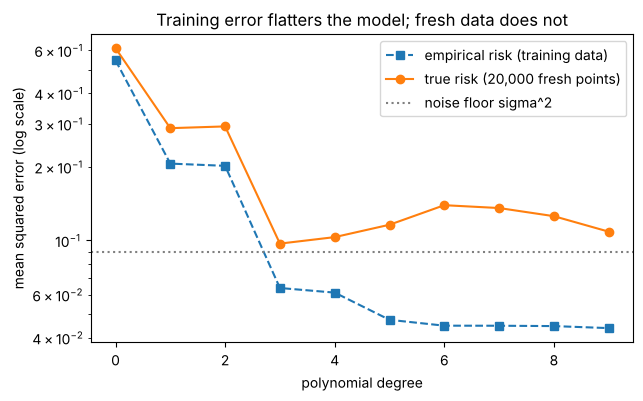

In [2]:
def f_true(x):
    return np.sin(2 * np.pi * x)

sigma = 0.3
n_train = 30
x_tr = rng.uniform(0, 1, n_train)
y_tr = f_true(x_tr) + sigma * rng.normal(size=n_train)
x_fresh = rng.uniform(0, 1, 20_000)                     # "the population"
y_fresh = f_true(x_fresh) + sigma * rng.normal(size=20_000)

degrees = np.arange(0, 10)
emp_risk, true_risk = [], []
for d in degrees:
    coef = np.polyfit(x_tr, y_tr, d)                    # least squares in the polynomial basis
    emp_risk.append(np.mean((np.polyval(coef, x_tr) - y_tr) ** 2))
    true_risk.append(np.mean((np.polyval(coef, x_fresh) - y_fresh) ** 2))
emp_risk, true_risk = np.array(emp_risk), np.array(true_risk)

print("degree  empirical risk (train MSE)   true risk (fresh MSE)   gap")
for d, e, t in zip(degrees, emp_risk, true_risk):
    print(f"{d:6d}  {e:26.4f}   {t:21.4f}   {t - e:6.3f}")
print(f"\nirreducible noise sigma^2 = {sigma**2:.3f}")

plt.semilogy(degrees, emp_risk, "s--", label="empirical risk (training data)")
plt.semilogy(degrees, true_risk, "o-", label="true risk (20,000 fresh points)")
plt.axhline(sigma ** 2, color="gray", ls=":", label="noise floor sigma^2")
plt.title("Training error flatters the model; fresh data does not")
plt.xlabel("polynomial degree"); plt.ylabel("mean squared error (log scale)"); plt.legend(); plt.show()

Training error falls monotonically with the degree — a richer class always fits the data
it was fitted on at least as well. The true risk falls to a minimum around degree 3–5 and then
rises as the polynomial starts fitting the noise; nothing ever gets below the noise floor
$\sigma^2 = 0.09$. Everything that follows in this module is about understanding, controlling
and *estimating* that gap.

**Try it yourself:** set `n_train = 300` and re-run. The gap shrinks for every degree — more
data is the one regulariser that costs no bias.

## 2. Ordinary least squares, three ways

For the model $y = \beta_0 + \beta_1 x$ on the five points of the concept guide, the OLS
coefficients can be reached by

1. **geometry** — the normal equations $X^\top X\hat\beta = X^\top y$ (the residual is
   orthogonal to the columns of $X$);
2. **calculus** — gradient descent on $\operatorname{RSS}(\beta) = \|y - X\beta\|^2$ with
   gradient $-2X^\top(y - X\beta)$;
3. **probability** — numerical maximum likelihood under $y_i \sim \mathcal{N}(\beta^\top x_i, \sigma^2)$.

We also compute the hat matrix $H$, leverages, $R^2$, $\hat\sigma^2 = \operatorname{RSS}/(n-p)$
and the standard error of the slope.

normal equations:    [1.3 0.9]
gradient descent:    [1.3 0.9]
maximum likelihood:  [1.3 0.9]   sigma_MLE^2 = 0.3800
np.linalg.lstsq:     [1.3 0.9]

fitted values: [2.2 3.1 4.  4.9 5.8]   residuals: [-0.2 -0.1  1.  -0.9  0.2]
X^T e =  [-0.  0.]  (residual orthogonal to the columns)
leverages h_ii: [0.6 0.3 0.2 0.3 0.6]   sum = 2.0 = p
RSS = 1.90, TSS = 10.00, R^2 = 0.810
sigma^2 (unbiased, RSS/(n-p)) = 0.6333   vs MLE RSS/n = 0.3800
SE(beta) = [0.8347 0.2517]   t for slope = 3.58, two-sided p = 0.037


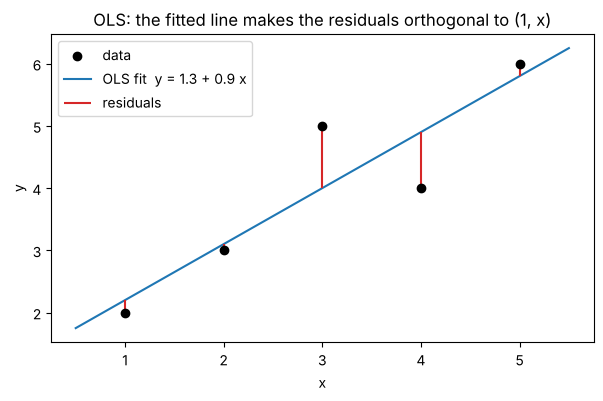

In [3]:
x5 = np.array([1., 2., 3., 4., 5.])
y5 = np.array([2., 3., 5., 4., 6.])
X5 = np.column_stack([np.ones(5), x5])
n, p = X5.shape

# (1) geometry: normal equations
beta_ne = np.linalg.solve(X5.T @ X5, X5.T @ y5)

# (2) calculus: gradient descent on RSS
beta_gd = np.zeros(2)
eta = 0.03                                  # must be < 2 / lambda_max(2 X^T X) ~ 0.0169*2
for _ in range(3000):
    beta_gd -= eta * (-2 * X5.T @ (y5 - X5 @ beta_gd)) / n

# (3) probability: maximise the Gaussian log-likelihood numerically over (beta0, beta1, log sigma)
def neg_loglik(theta):
    b, log_s = theta[:2], theta[2]
    return -np.sum(stats.norm.logpdf(y5, loc=X5 @ b, scale=np.exp(log_s)))
res = optimize.minimize(neg_loglik, x0=np.array([0., 0., 0.]), method="BFGS")
beta_ml, sigma_ml = res.x[:2], np.exp(res.x[2])

print("normal equations:   ", beta_ne)
print("gradient descent:   ", beta_gd)
print("maximum likelihood: ", beta_ml, "  sigma_MLE^2 = %.4f" % sigma_ml**2)
print("np.linalg.lstsq:    ", np.linalg.lstsq(X5, y5, rcond=None)[0])

# hat matrix, residuals, fit statistics
H = X5 @ np.linalg.solve(X5.T @ X5, X5.T)
y_hat = H @ y5
e = y5 - y_hat
rss, tss = e @ e, ((y5 - y5.mean()) ** 2).sum()
sigma2_hat = rss / (n - p)
se = np.sqrt(np.diag(sigma2_hat * np.linalg.inv(X5.T @ X5)))
print("\nfitted values:", y_hat, "  residuals:", e)
print("X^T e = ", X5.T @ e, " (residual orthogonal to the columns)")
print("leverages h_ii:", np.diag(H), "  sum = %.1f = p" % np.trace(H))
print("RSS = %.2f, TSS = %.2f, R^2 = %.3f" % (rss, tss, 1 - rss / tss))
print("sigma^2 (unbiased, RSS/(n-p)) = %.4f   vs MLE RSS/n = %.4f" % (sigma2_hat, rss / n))
print("SE(beta) =", se, "  t for slope = %.2f, two-sided p = %.3f"
      % (beta_ne[1] / se[1], 2 * stats.t.sf(beta_ne[1] / se[1], df=n - p)))

xx = np.linspace(0.5, 5.5, 50)
plt.scatter(x5, y5, color="k", zorder=3, label="data")
plt.plot(xx, beta_ne[0] + beta_ne[1] * xx, label="OLS fit  y = 1.3 + 0.9 x")
plt.vlines(x5, y_hat, y5, color="tab:red", label="residuals")
plt.title("OLS: the fitted line makes the residuals orthogonal to (1, x)")
plt.xlabel("x"); plt.ylabel("y"); plt.legend(); plt.show()

All three routes land on $\hat\beta = (1.3, 0.9)$, and `lstsq` agrees. Note the two noise
estimates: maximum likelihood divides the RSS by $n$ and is biased low; the unbiased estimate
divides by $n - p = 3$. The leverages $0.6, 0.3, 0.2, 0.3, 0.6$ sum to $p = 2$ and are largest
at the ends of the $x$-range — those points pull hardest on the line, which matters again in
Sections 9 and 10.

## 3. Basis expansion and overfitting

A model that is linear in its *coefficients* can be as curved as you like in $x$: replace $x$
by features $\phi(x) = (1, x, x^2, \dots, x^k)$ and run the same least squares. Two things go
wrong when $k$ is large. Statistically, a degree-9 polynomial through 10 points interpolates
them exactly and oscillates wildly in between. Numerically, the columns $x^k$ have wildly
different scales, so the design matrix is badly conditioned (Module 03) unless you
**standardise** $x$ first.

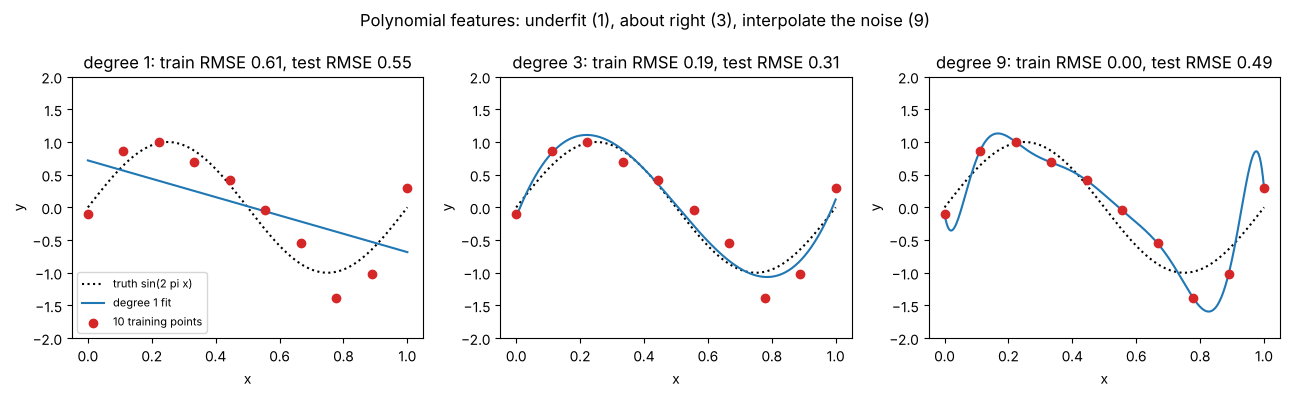

degree 3: condition number raw x =  1.617e+03   standardised x =  6.149e+00
degree 6: condition number raw x =  6.540e+06   standardised x =  1.177e+02
degree 9: condition number raw x =  9.971e+10   standardised x =  4.620e+03


In [4]:
x10 = np.linspace(0, 1, 10)
y10 = f_true(x10) + sigma * rng.normal(size=10)
x_test = rng.uniform(0, 1, 2000)
y_test = f_true(x_test) + sigma * rng.normal(size=2000)
grid = np.linspace(0, 1, 300)

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, d in zip(axes, [1, 3, 9]):
    coef = np.polyfit(x10, y10, d)
    tr_rmse = np.sqrt(np.mean((np.polyval(coef, x10) - y10) ** 2))
    te_rmse = np.sqrt(np.mean((np.polyval(coef, x_test) - y_test) ** 2))
    ax.plot(grid, f_true(grid), "k:", label="truth sin(2 pi x)")
    ax.plot(grid, np.polyval(coef, grid), label=f"degree {d} fit")
    ax.scatter(x10, y10, color="tab:red", zorder=3, label="10 training points")
    ax.set_ylim(-2, 2); ax.set_title(f"degree {d}: train RMSE {tr_rmse:.2f}, test RMSE {te_rmse:.2f}")
    ax.set_xlabel("x"); ax.set_ylabel("y")
axes[0].legend(loc="lower left", fontsize=8)
fig.suptitle("Polynomial features: underfit (1), about right (3), interpolate the noise (9)")
plt.tight_layout(); plt.show()

# conditioning of the design matrix, raw versus standardised x
def poly_design(x, degree):
    return np.column_stack([x ** k for k in range(degree + 1)])
x_raw = np.linspace(0, 10, 11)
x_std = (x_raw - x_raw.mean()) / x_raw.std()
for d in [3, 6, 9]:
    print(f"degree {d}: condition number raw x = {np.linalg.cond(poly_design(x_raw, d)):10.3e}"
          f"   standardised x = {np.linalg.cond(poly_design(x_std, d)):10.3e}")

The degree-9 curve passes through every training point (train RMSE 0.00) yet its error on
fresh data (0.49) is far worse than the cubic's (0.31): it has memorised the noise, and the
wiggles between the points are the price. Degree 1 cannot bend at all and is worst of the
three on both counts. The condition numbers show the second problem: with raw $x \in [0, 10]$
the degree-9 design matrix is conditioned like $10^{11}$, so you lose about eleven digits in
the solve; standardising brings it down by seven orders of magnitude. **Always standardise
before adding powers or a penalty** — the next two sections rely on it.

**Try it yourself:** change the training sample to 30 points (`np.linspace(0, 1, 30)`).
Degree 9 is no longer an interpolant; how much does its test RMSE improve?

## 4. Ridge regression: shrinkage along singular directions

Ridge minimises $\|y - X\beta\|^2 + \lambda\|\beta\|^2$ and has the closed form
$\hat\beta_\lambda = (X^\top X + \lambda I)^{-1}X^\top y$. Through the SVD $X = UDV^\top$,

$$\hat\beta_\lambda = \sum_j \frac{d_j}{d_j^2 + \lambda}\,\langle u_j, y\rangle\,v_j
\qquad\text{so each OLS component is multiplied by the filter factor } \frac{d_j^2}{d_j^2 + \lambda},$$

and the effective degrees of freedom are $\operatorname{df}(\lambda) = \sum_j d_j^2/(d_j^2+\lambda)$.

The design below has six standardised features of which $x_1$ is almost a copy of $x_0$
(correlation 0.98) and $x_3$ is moderately correlated with $x_2$. The true coefficients are
$(2, 0, -1.5, 0.8, 0, 0)$.

correlation(x0, x1) = 0.984
true coefficients: [ 2.   0.  -1.5  0.8  0.   0. ]
OLS:               [ 3.6006 -1.4628 -1.5471  0.9288 -0.1116 -0.2885]   (x0 and x1 fight over the shared signal)
ridge lambda=    1: [ 2.2359 -0.1317 -1.4745  0.9108 -0.1008 -0.2547]  ||beta|| = 2.85
ridge lambda=   10: [ 1.1409  0.735  -1.0897  0.6076 -0.1041 -0.2227]  ||beta|| = 1.86
ridge lambda=  100: [ 0.5217  0.4835 -0.3276  0.0613 -0.0469 -0.1185]  ||beta|| = 0.80
(closed form == SVD formula == sklearn.linear_model.Ridge for every lambda)

singular values of X: [11.3563 10.0413  8.1481  6.3631  4.7378  0.9368]
smallest right singular vector v_6 (the direction the data barely constrain): [-0.7075  0.7062  0.0067  0.0187  0.0077  0.0177]


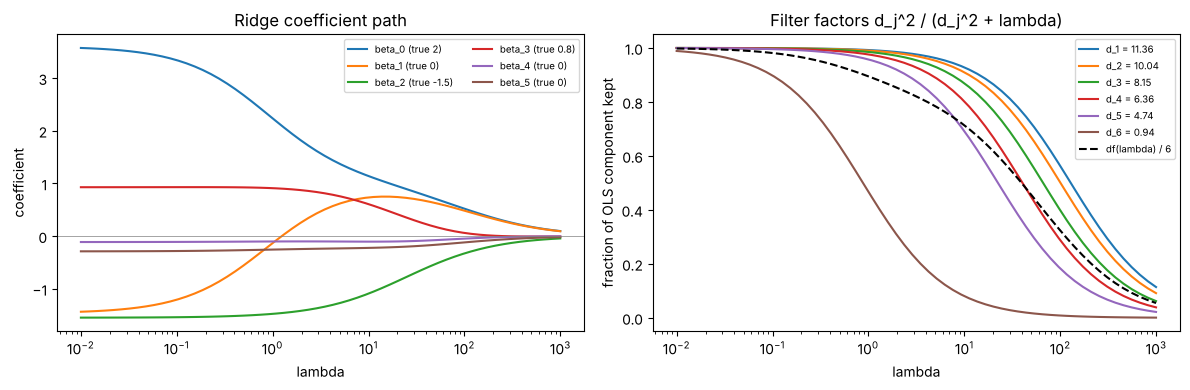

In [5]:
from sklearn.linear_model import Ridge

def make_design(n=60, seed=0):
    g = np.random.default_rng(seed)
    Z = g.normal(size=(n, 6))
    Z[:, 1] = Z[:, 0] + 0.2 * g.normal(size=n)          # x1 is a noisy copy of x0
    Z[:, 3] = 0.6 * Z[:, 2] + 0.8 * g.normal(size=n)    # x3 partly overlaps x2
    X = (Z - Z.mean(axis=0)) / Z.std(axis=0)            # standardise
    beta_true = np.array([2., 0., -1.5, 0.8, 0., 0.])
    y = X @ beta_true + 1.5 * g.normal(size=n)
    return X, y - y.mean(), beta_true                   # centred y: no intercept needed

Xr, yr, beta_true = make_design()
print("correlation(x0, x1) = %.3f" % np.corrcoef(Xr[:, 0], Xr[:, 1])[0, 1])

def ridge_closed_form(X, y, lam):
    return np.linalg.solve(X.T @ X + lam * np.eye(X.shape[1]), X.T @ y)

def ridge_svd(X, y, lam):
    U, d, Vt = np.linalg.svd(X, full_matrices=False)
    return Vt.T @ ((d / (d ** 2 + lam)) * (U.T @ y))

beta_ols = ridge_closed_form(Xr, yr, 0.0)
print("true coefficients:", beta_true)
print("OLS:              ", beta_ols, "  (x0 and x1 fight over the shared signal)")
for lam in [1., 10., 100.]:
    b = ridge_closed_form(Xr, yr, lam)
    assert np.allclose(b, ridge_svd(Xr, yr, lam))
    assert np.allclose(b, Ridge(alpha=lam, fit_intercept=False).fit(Xr, yr).coef_)
    print(f"ridge lambda={lam:5.0f}:", b, " ||beta|| = %.2f" % np.linalg.norm(b))
print("(closed form == SVD formula == sklearn.linear_model.Ridge for every lambda)")

# coefficient path, filter factors and effective degrees of freedom
lams = np.logspace(-2, 3, 60)
path = np.array([ridge_closed_form(Xr, yr, lam) for lam in lams])
U, d, Vt = np.linalg.svd(Xr, full_matrices=False)
print("\nsingular values of X:", d)
print("smallest right singular vector v_6 (the direction the data barely constrain):", Vt[-1])

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for j in range(6):
    axes[0].semilogx(lams, path[:, j], label=f"beta_{j} (true {beta_true[j]:g})")
axes[0].axhline(0, color="gray", lw=0.5)
axes[0].set_title("Ridge coefficient path"); axes[0].set_xlabel("lambda"); axes[0].set_ylabel("coefficient")
axes[0].legend(fontsize=7, ncol=2)
for j in range(6):
    axes[1].semilogx(lams, d[j] ** 2 / (d[j] ** 2 + lams), label=f"d_{j+1} = {d[j]:.2f}")
axes[1].semilogx(lams, (d[:, None] ** 2 / (d[:, None] ** 2 + lams[None, :])).sum(0) / 6, "k--", label="df(lambda) / 6")
axes[1].set_title("Filter factors d_j^2 / (d_j^2 + lambda)"); axes[1].set_xlabel("lambda"); axes[1].set_ylabel("fraction of OLS component kept")
axes[1].legend(fontsize=7)
plt.tight_layout(); plt.show()

OLS splits the shared signal between $x_0$ and $x_1$ almost arbitrarily ($3.60$ and $-1.46$
where the truth is $2$ and $0$ — note the opposite signs). The smallest singular value,
$d_6 \approx 0.94$, belongs to the direction $v_6 \approx (x_1 - x_0)/\sqrt2$ — exactly the
"difference" the data cannot resolve — and its filter factor ($0.47$ at $\lambda = 1$, $0.08$
at $\lambda = 10$) is the first to collapse as $\lambda$ grows. By $\lambda = 10$ the two
coefficients are $1.14$ and $0.74$: both positive, both wrong individually, but their *sum*
($1.88$, the quantity the data actually determine) is close to the true $2$. The other
directions, with $d_j^2$ between 22 and 129, keep 70–93 % of their weight at $\lambda = 10$ and
are only seriously shrunk when $\lambda$ reaches their scale. The effective degrees of freedom
slide from 6 towards 0: $5.4$ at $\lambda = 1$, $4.3$ at $\lambda = 10$, $1.9$ at $\lambda = 100$.

**Try it yourself:** in the Bayesian reading $\lambda = \sigma^2/\tau^2$. The noise here has
$\sigma = 1.5$; which prior standard deviation $\tau$ on the coefficients corresponds to
$\lambda = 10$? Does it look reasonable next to the true coefficients?

## 5. Lasso: soft-thresholding and coordinate descent

The lasso minimises $\tfrac12\|y - X\beta\|^2 + \lambda\|\beta\|_1$. For an orthonormal design
the solution is the **soft-thresholding** of the OLS coefficients,
$S_\lambda(z) = \operatorname{sign}(z)\max(|z| - \lambda, 0)$; in general **coordinate descent**
applies the same operator one coordinate at a time to the partial residual:

$$\beta_j \leftarrow \frac{S_\lambda\!\left(x_j^\top r^{(j)}\right)}{\|x_j\|^2},
\qquad r^{(j)} = y - \sum_{k\ne j} x_k\beta_k .$$

scikit-learn's `Lasso(alpha)` minimises $\frac{1}{2n}\|y - X\beta\|^2 + \alpha\|\beta\|_1$,
so $\lambda = n\alpha$.

soft_threshold([3, -0.5, 1.2], 1) = [ 2.  -0.   0.2]
lasso lambda=   5: [ 2.0046  0.     -1.3268  0.7462 -0.0416 -0.1961]   max |ours - sklearn| = 1.0e-10
lasso lambda=  20: [ 1.562   0.     -0.6632  0.053  -0.     -0.    ]   max |ours - sklearn| = 5.4e-11
lasso lambda=  60: [ 0.7945  0.     -0.     -0.     -0.     -0.    ]   max |ours - sklearn| = 2.2e-16
true:               [ 2.   0.  -1.5  0.8  0.   0. ]


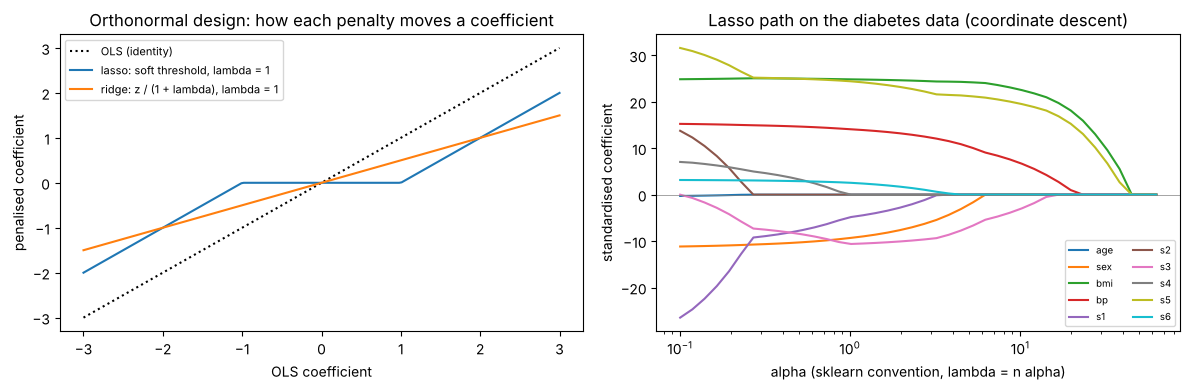

alpha =   0.10:  9 non-zero coefficients
alpha =   0.38:  8 non-zero coefficients
alpha =   1.41:  7 non-zero coefficients
alpha =   5.29:  5 non-zero coefficients
alpha =  19.84:  3 non-zero coefficients


In [6]:
from sklearn.linear_model import Lasso

def soft_threshold(z, lam):
    return np.sign(z) * np.maximum(np.abs(z) - lam, 0.0)

def lasso_cd(X, y, lam, n_iter=500):
    n, p = X.shape
    beta = np.zeros(p)
    r = y.copy()                                    # full residual y - X beta
    col_sq = (X ** 2).sum(axis=0)
    for _ in range(n_iter):
        for j in range(p):
            r += X[:, j] * beta[j]                  # partial residual without feature j
            beta[j] = soft_threshold(X[:, j] @ r, lam) / col_sq[j]
            r -= X[:, j] * beta[j]
    return beta

print("soft_threshold([3, -0.5, 1.2], 1) =", soft_threshold(np.array([3., -0.5, 1.2]), 1.0))
for lam in [5., 20., 60.]:
    b_cd = lasso_cd(Xr, yr, lam)
    b_sk = Lasso(alpha=lam / len(yr), fit_intercept=False, tol=1e-10, max_iter=100_000).fit(Xr, yr).coef_
    print(f"lasso lambda={lam:4.0f}: {b_cd}   max |ours - sklearn| = {np.abs(b_cd - b_sk).max():.1e}")
print("true:              ", beta_true)

# lasso path on the diabetes data (10 standardised features, centred target)
Xd, yd = load_diabetes(return_X_y=True)
names = load_diabetes().feature_names
Xd_s = (Xd - Xd.mean(axis=0)) / Xd.std(axis=0)
yd_c = yd - yd.mean()
alphas = np.logspace(-1, 1.8, 40)
lasso_path = np.array([lasso_cd(Xd_s, yd_c, a * len(yd_c), n_iter=300) for a in alphas])
n_nonzero = (np.abs(lasso_path) > 1e-8).sum(axis=1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
z = np.linspace(-3, 3, 200)
axes[0].plot(z, z, "k:", label="OLS (identity)")
axes[0].plot(z, soft_threshold(z, 1.0), label="lasso: soft threshold, lambda = 1")
axes[0].plot(z, z / 2, label="ridge: z / (1 + lambda), lambda = 1")
axes[0].set_title("Orthonormal design: how each penalty moves a coefficient")
axes[0].set_xlabel("OLS coefficient"); axes[0].set_ylabel("penalised coefficient"); axes[0].legend(fontsize=8)
for j in range(10):
    axes[1].semilogx(alphas, lasso_path[:, j], label=names[j])
axes[1].axhline(0, color="gray", lw=0.5)
axes[1].set_title("Lasso path on the diabetes data (coordinate descent)")
axes[1].set_xlabel("alpha (sklearn convention, lambda = n alpha)"); axes[1].set_ylabel("standardised coefficient")
axes[1].legend(fontsize=7, ncol=2)
plt.tight_layout(); plt.show()
for a, k in zip(alphas[::8], n_nonzero[::8]):
    print(f"alpha = {a:6.2f}: {k:2d} non-zero coefficients")

Our twenty-line coordinate descent matches scikit-learn to about $10^{-10}$. On the synthetic
design the lasso does what ridge cannot: already at $\lambda = 5$ it sets the coefficient of
the near-duplicate $x_1$ to exactly zero and gives $x_0$ its full weight ($2.00$, the truth);
at $\lambda = 20$ three more irrelevant coefficients are exactly zero while the survivors are
shrunk. Which of two near-duplicates survives is decided by tiny differences in correlation
with $y$ — the *choice* between them is arbitrary, the *selection* of the pair is not. On the
diabetes data the path shows the order in which features enter as the penalty relaxes:
`bmi` and `s5` (a serum triglyceride measure) first, then blood pressure and `s3`, then sex,
`s6` and `s1`; `s4`, `s2` and `age` stay at zero for most of the path because they are highly
correlated with features already in the model (`s2` with `s1` at $0.90$, `s4` with `s3`) and add
little once those are in.

**Try it yourself:** add a ridge term to turn `lasso_cd` into an elastic net — the update
becomes $S_\lambda(x_j^\top r^{(j)})/(\|x_j\|^2 + \lambda_2)$. With $\lambda_2 = 20$, do $x_0$
and $x_1$ now share the weight?

## 6. Logistic regression by Newton's method (IRLS)

For binary $y$, $p(x) = \sigma(\beta^\top x)$ and the negative log-likelihood
$\ell(\beta) = \sum_i[\log(1 + e^{\beta^\top x_i}) - y_i\beta^\top x_i]$ has

$$\nabla\ell = X^\top(p - y), \qquad \nabla^2\ell = X^\top W X, \quad W = \operatorname{diag}(p_i(1-p_i)).$$

Newton's step $\beta \leftarrow \beta - (X^\top WX)^{-1}X^\top(p - y)$ is a weighted least-squares
fit, hence *iteratively reweighted least squares*. We add an L2 penalty $\frac{\lambda}{2}\|\beta_{1:}\|^2$
(not on the intercept) and fit the standardised breast-cancer data (569 tumours, 30 features,
target 1 = benign). scikit-learn's `LogisticRegression(C)` solves the same problem with
$\lambda = 1/C$.

In [7]:
from sklearn.linear_model import LogisticRegression

bc = load_breast_cancer()
Xb = (bc.data - bc.data.mean(axis=0)) / bc.data.std(axis=0)
yb = bc.target.astype(float)
Xb1 = np.column_stack([np.ones(len(yb)), Xb])          # intercept column first

def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-z))

def logistic_nll(beta, X, y, lam, pen):
    z = X @ beta
    return np.sum(np.logaddexp(0, z) - y * z) + 0.5 * lam * np.sum(pen * beta ** 2)

def logistic_newton(X, y, lam=1.0, n_iter=50, tol=1e-10):
    beta = np.zeros(X.shape[1])
    pen = np.ones(X.shape[1]); pen[0] = 0.0            # do not penalise the intercept
    history = [logistic_nll(beta, X, y, lam, pen)]
    for it in range(n_iter):
        p = sigmoid(X @ beta)
        grad = X.T @ (p - y) + lam * pen * beta
        W = p * (1 - p)
        Hess = X.T @ (W[:, None] * X) + lam * np.diag(pen)
        step = np.linalg.solve(Hess, grad)
        beta = beta - step
        history.append(logistic_nll(beta, X, y, lam, pen))
        if np.abs(step).max() < tol:
            break
    return beta, np.array(history)

lam = 1.0
beta_nt, hist = logistic_newton(Xb1, yb, lam=lam)
print("penalised negative log-likelihood per Newton iteration:")
print(np.round(hist, 4))

clf = LogisticRegression(C=1.0 / lam, tol=1e-10, max_iter=10_000).fit(Xb, yb)
beta_sk = np.r_[clf.intercept_, clf.coef_.ravel()]
print("\nmax |Newton - sklearn| = %.1e" % np.abs(beta_nt - beta_sk).max())
p_hat = sigmoid(Xb1 @ beta_nt)
print("training accuracy = %.4f" % np.mean((p_hat > 0.5) == yb))
print("calibration: mean predicted probability %.4f  vs  observed rate %.4f" % (p_hat.mean(), yb.mean()))
order = np.argsort(-np.abs(beta_nt[1:]))[:5]
print("\nlargest standardised effects (odds ratio per standard deviation of the feature):")
for j in order:
    print(f"  {bc.feature_names[j]:24s} beta = {beta_nt[1 + j]:7.3f}   odds ratio = {np.exp(beta_nt[1 + j]):.3f}")

penalised negative log-likelihood per Newton iteration:
[394.4007 138.426   83.5774  57.9046  43.6378  38.6618  37.7936  37.759
  37.7589  37.7589  37.7589]

max |Newton - sklearn| = 1.1e-06
training accuracy = 0.9877
calibration: mean predicted probability 0.6274  vs  observed rate 0.6274

largest standardised effects (odds ratio per standard deviation of the feature):
  worst texture            beta =  -1.315   odds ratio = 0.269
  radius error             beta =  -1.291   odds ratio = 0.275
  worst radius             beta =  -1.029   odds ratio = 0.357
  area error               beta =  -1.013   odds ratio = 0.363
  worst area               beta =  -1.011   odds ratio = 0.364


Newton converges in about ten iterations — the quadratic convergence shows as the number of
correct digits roughly doubling each step near the end — and lands on the same coefficients as
scikit-learn. The calibration identity $\sum_i p_i = \sum_i y_i$ holds exactly: with an
intercept, the score equation forces the predicted probabilities to average to the observed
rate. Each coefficient is a log odds ratio per standard deviation: a tumour one standard
deviation higher in "worst texture" has about $0.27\times$ the odds of being benign, all else
equal.

### Separable data: why the unpenalised MLE does not exist

If a hyperplane separates the classes perfectly, scaling $\beta$ up only makes the likelihood
better, so plain gradient ascent never stops. We compare eight points that are separable with
the same points after two labels are swapped.

separable, lambda = 0      after 3000 steps: beta = [ 0.     13.2665],  ||beta|| =  13.27,  NLL = 0.0026
overlapping, lambda = 0    after 3000 steps: beta = [0.     0.9705],  ||beta|| =   0.97,  NLL = 4.2305
separable, lambda = 1      after 3000 steps: beta = [-0.      1.3503],  ||beta|| =   1.35,  NLL = 1.6617


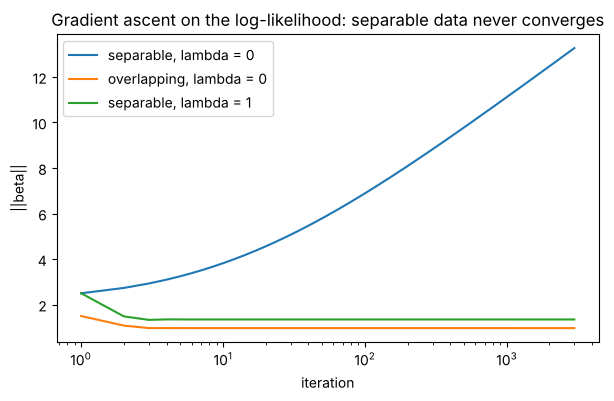

In [8]:
xs = np.array([-2., -1.5, -1., -0.5, 0.5, 1., 1.5, 2.])
Xs1 = np.column_stack([np.ones(8), xs])
y_sep = (xs > 0).astype(float)                         # perfectly separable at x = 0
y_over = y_sep.copy(); y_over[2] = 1.0; y_over[5] = 0.0  # two labels swapped: overlapping

def gradient_ascent(X, y, lam=0.0, n_iter=3000, lr=0.5):
    beta = np.zeros(2); norms = []
    for _ in range(n_iter):
        p = sigmoid(X @ beta)
        beta += lr * (X.T @ (y - p) - lam * np.r_[0.0, beta[1]])
        norms.append(np.linalg.norm(beta))
    return beta, np.array(norms)

runs = {"separable, lambda = 0": gradient_ascent(Xs1, y_sep),
        "overlapping, lambda = 0": gradient_ascent(Xs1, y_over),
        "separable, lambda = 1": gradient_ascent(Xs1, y_sep, lam=1.0)}
for name, (b, norms) in runs.items():
    p = sigmoid(Xs1 @ b)
    nll = -np.sum(np.where(name.startswith("sep"), y_sep, y_over) * np.log(p)
                  + (1 - np.where(name.startswith("sep"), y_sep, y_over)) * np.log(1 - p))
    print(f"{name:26s} after 3000 steps: beta = {b},  ||beta|| = {norms[-1]:6.2f},  NLL = {nll:.4f}")
    plt.semilogx(np.arange(1, 3001), norms, label=name)
plt.title("Gradient ascent on the log-likelihood: separable data never converges")
plt.xlabel("iteration"); plt.ylabel("||beta||"); plt.legend(); plt.show()

On the overlapping data the coefficients settle within a hundred steps. On the separable
data the norm keeps growing — slowly, because the gradient $X^\top(y - p)$ shrinks as the
probabilities saturate, but without limit; the negative log-likelihood creeps towards zero and
`np.linalg.solve` in a Newton implementation would eventually hit a singular $X^\top WX$.
The L2 penalty makes the objective strictly convex and the fit stops at a finite $\beta$. This
is why scikit-learn regularises by default and why "my logistic regression coefficients are
huge" usually means "my classes are (nearly) separable".

**Try it yourself:** separable data in two dimensions is common when $p$ is large relative
to $n$. Fit `logistic_newton` with `lam=0.0` to the first 100 rows of `Xb1` only; watch the
coefficients and the number of iterations.

## 7. Generalised linear models: Poisson regression

A GLM pairs an exponential-family distribution with a link function; with the canonical link
the score equations are always $X^\top(y - \mu) = 0$ and Newton's method is IRLS with
$W_{ii} = \operatorname{Var}(y_i)$. For counts, $y_i \sim \text{Poisson}(\mu_i)$ with
$\log\mu_i = \log t_i + \beta^\top x_i$, where $t_i$ is the **exposure** (an offset with
coefficient fixed to 1). Below: synthetic motor-insurance claims — each policy has an exposure
between 0.2 and 1 years, a standardised driver-age score and an urban indicator, with true
coefficients $(-0.3, -0.35, 0.5)$. We fit by plain gradient ascent, by Newton, and with
`sklearn.linear_model.PoissonRegressor`, then compute the deviance.

policies: 600, total claims: 352, share with zero claims: 0.62


true coefficients:       [-0.3  -0.35  0.5 ]
gradient ascent (2000):  [-0.3251 -0.4222  0.4414]
Newton ( 6 iterations):   [-0.3251 -0.4222  0.4414]
sklearn PoissonRegressor: [-0.3251 -0.4222  0.4414]
rate ratios exp(beta):    [0.7224 0.6556 1.5549]  -> urban policies claim 55% more often

residual deviance = 627.8 on 597 degrees of freedom   (null deviance 714.0)


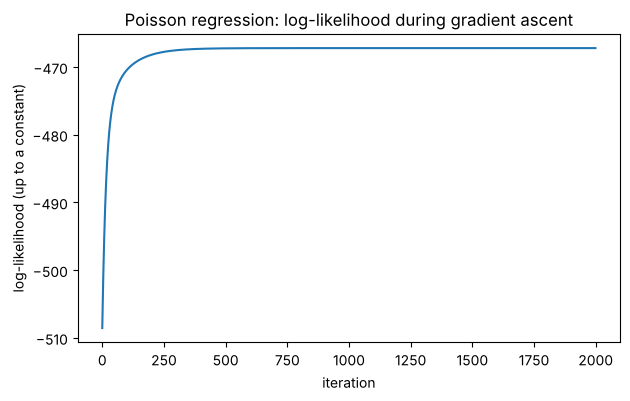

In [9]:
from sklearn.linear_model import PoissonRegressor

n_pol = 600
age_z = rng.normal(size=n_pol)
urban = rng.binomial(1, 0.4, size=n_pol).astype(float)
exposure = rng.uniform(0.2, 1.0, size=n_pol)
Xp = np.column_stack([np.ones(n_pol), age_z, urban])
beta_pois_true = np.array([-0.3, -0.35, 0.5])
claims = rng.poisson(exposure * np.exp(Xp @ beta_pois_true)).astype(float)
offset = np.log(exposure)
print("policies: %d, total claims: %d, share with zero claims: %.2f" % (n_pol, claims.sum(), (claims == 0).mean()))

def poisson_loglik(beta, X, y, offset):
    eta = offset + X @ beta
    return np.sum(y * eta - np.exp(eta))               # up to the constant -sum(log y!)

# (a) gradient ascent on the log-likelihood: gradient X^T (y - mu)
beta_ga = np.zeros(3); ll_hist = []
for it in range(2000):
    mu = np.exp(offset + Xp @ beta_ga)
    beta_ga += 0.05 * Xp.T @ (claims - mu) / n_pol
    ll_hist.append(poisson_loglik(beta_ga, Xp, claims, offset))

# (b) Newton / IRLS: Hessian X^T diag(mu) X
beta_nt = np.zeros(3)
for it in range(25):
    mu = np.exp(offset + Xp @ beta_nt)
    step = np.linalg.solve(Xp.T @ (mu[:, None] * Xp), Xp.T @ (claims - mu))
    beta_nt += step
    if np.abs(step).max() < 1e-12:
        break

# (c) scikit-learn: model the *rate* y / t with sample weights t (equivalent to the offset)
pr = PoissonRegressor(alpha=0.0, tol=1e-12, max_iter=10_000).fit(Xp[:, 1:], claims / exposure, sample_weight=exposure)
beta_sk = np.r_[pr.intercept_, pr.coef_]

print("true coefficients:      ", beta_pois_true)
print("gradient ascent (2000): ", beta_ga)
print("Newton (%2d iterations):  " % (it + 1), beta_nt)
print("sklearn PoissonRegressor:", beta_sk)
print("rate ratios exp(beta):   ", np.exp(beta_nt), " -> urban policies claim %.0f%% more often" % (100 * (np.exp(beta_nt[2]) - 1)))

def poisson_deviance(y, mu):
    terms = np.where(y > 0, y * np.log(np.where(y > 0, y, 1.0) / mu), 0.0) - (y - mu)
    return 2 * terms.sum()

mu_hat = np.exp(offset + Xp @ beta_nt)
mu_null = exposure * claims.sum() / exposure.sum()     # intercept-only model: one overall rate
print("\nresidual deviance = %.1f on %d degrees of freedom   (null deviance %.1f)"
      % (poisson_deviance(claims, mu_hat), n_pol - 3, poisson_deviance(claims, mu_null)))

plt.plot(ll_hist)
plt.title("Poisson regression: log-likelihood during gradient ascent")
plt.xlabel("iteration"); plt.ylabel("log-likelihood (up to a constant)"); plt.show()

Three fits, one answer. Newton needs a handful of iterations where gradient ascent needs
hundreds, because the Hessian $X^\top\operatorname{diag}(\mu)X$ rescales each direction
correctly (Module 05). The coefficients are read as **rate ratios**: $e^{\hat\beta_{\text{urban}}}$
is the factor by which the claim rate is multiplied for urban drivers. The residual deviance is
close to its degrees of freedom, as it should be for data that really are Poisson; for real
claims it is typically 1.5–2 times larger (overdispersion), a signal to inflate the standard
errors.

## 8. The bias–variance decomposition, measured

For $y = f(x) + \varepsilon$ and a model $\hat f$ fitted on a random training set $D$,

$$\mathbb{E}\big[(y - \hat f(x))^2\big] = \sigma^2 + \big(f(x) - \mathbb{E}_D[\hat f(x)]\big)^2 + \mathbb{E}_D\big[(\hat f(x) - \mathbb{E}_D[\hat f(x)])^2\big].$$

The expectation over $D$ is exactly what a simulation can approximate: draw 200 training sets
of $n = 30$ points, fit a polynomial of each degree to each, and look at the spread of the 200
fitted curves on a test grid. We also measure the test error directly and check that the
three terms add up to it.

degree   bias^2   variance   noise   bias^2+var+noise   measured test MSE
     0   0.4951     0.0224   0.090             0.6075              0.6099
     1   0.2038     0.0234   0.090             0.3173              0.3167
     2   0.2057     0.0489   0.090             0.3446              0.3449
     3   0.0050     0.0162   0.090             0.1112              0.1107
     4   0.0058     0.0356   0.090             0.1314              0.1306
     5   0.0008     0.0456   0.090             0.1364              0.1358
     6   0.0024     0.1318   0.090             0.2242              0.2231
     7   0.0046     0.2991   0.090             0.3937              0.3950
     8   0.0016     2.6464   0.090             2.7380              2.7269
     9   0.0351     5.2210   0.090             5.3461              5.3507
    10   0.1662    44.0099   0.090            44.2661             44.2718


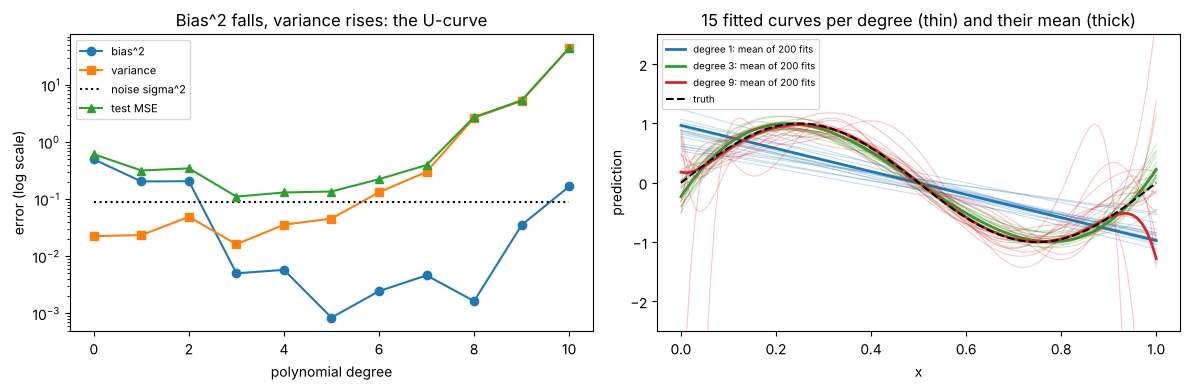

In [10]:
def bias_variance(degree, n_train=30, n_rep=200, sigma=0.3, seed=0):
    g = np.random.default_rng(seed)
    x_grid = np.linspace(0, 1, 101)
    f_grid = f_true(x_grid)
    preds = np.empty((n_rep, len(x_grid)))
    test_mse = np.empty(n_rep)
    for r in range(n_rep):
        x = g.uniform(0, 1, n_train)
        y = f_true(x) + sigma * g.normal(size=n_train)
        coef = np.polyfit(x, y, degree)
        preds[r] = np.polyval(coef, x_grid)
        y_grid = f_grid + sigma * g.normal(size=len(x_grid))          # fresh noisy targets
        test_mse[r] = np.mean((y_grid - preds[r]) ** 2)
    bias2 = np.mean((preds.mean(axis=0) - f_grid) ** 2)
    var = np.mean(preds.var(axis=0))
    return bias2, var, test_mse.mean(), preds, x_grid

degs = np.arange(0, 11)
table = np.array([bias_variance(d)[:3] for d in degs])
print("degree   bias^2   variance   noise   bias^2+var+noise   measured test MSE")
for d, (b2, v, m) in zip(degs, table):
    print(f"{d:6d}  {b2:7.4f}  {v:9.4f}  {sigma**2:6.3f}  {b2 + v + sigma**2:17.4f}  {m:18.4f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].semilogy(degs, table[:, 0], "o-", label="bias^2")
axes[0].semilogy(degs, table[:, 1], "s-", label="variance")
axes[0].semilogy(degs, np.full_like(degs, sigma ** 2, dtype=float), "k:", label="noise sigma^2")
axes[0].semilogy(degs, table[:, 2], "^-", label="test MSE")
axes[0].set_title("Bias^2 falls, variance rises: the U-curve"); axes[0].set_xlabel("polynomial degree"); axes[0].set_ylabel("error (log scale)")
axes[0].legend(fontsize=8)
for d, c in [(1, "tab:blue"), (3, "tab:green"), (9, "tab:red")]:
    _, _, _, preds, x_grid = bias_variance(d)
    for r in range(15):
        axes[1].plot(x_grid, preds[r], color=c, alpha=0.25, lw=0.8)
    axes[1].plot(x_grid, preds.mean(axis=0), color=c, lw=2, label=f"degree {d}: mean of 200 fits")
axes[1].plot(x_grid, f_true(x_grid), "k--", label="truth")
axes[1].set_ylim(-2.5, 2.5); axes[1].set_title("15 fitted curves per degree (thin) and their mean (thick)")
axes[1].set_xlabel("x"); axes[1].set_ylabel("prediction"); axes[1].legend(fontsize=7)
plt.tight_layout(); plt.show()

The decomposition is exact up to Monte Carlo error: the sum of the three estimated terms
tracks the measured test MSE in every row. Degree 1 is all bias — the mean of its 200 fits is
a straight line through a sine. Degree 9 is all variance — the individual fits swing by
several units near the edges of the interval, though their *average* is close to the truth.
Degree 3 to 5 balances the two. Regularisation moves along the same trade-off without
changing the degree: increasing $\lambda$ in ridge raises bias and lowers variance exactly
as decreasing the degree does here.

**Try it yourself:** set `n_train=300` inside the call. The variance of every degree drops
by roughly a factor of 10 (it scales like $p/n$) and the bottom of the U moves to a higher
degree — with more data you can afford a more flexible model.

## 9. Cross-validation, the leave-one-out shortcut and learning curves

$k$-fold cross-validation estimates the true risk by holding out each fold in turn. We use it
to choose $\lambda$ for ridge on the diabetes data with all 65 degree-2 polynomial features
(10 linear, 10 squares, 45 interactions) — a setting where regularisation matters. Error bars
are the standard error of the fold means; the **one-standard-error rule** picks the largest
$\lambda$ whose error is within one standard error of the minimum.

design matrix with degree-2 features: (442, 65)
lambda minimising CV error: 100.0  (CV RMSE 55.62)
one-standard-error rule:    251.2  (CV RMSE 56.24)
for comparison, OLS on the 65 features (lambda -> 0): CV RMSE 59.86


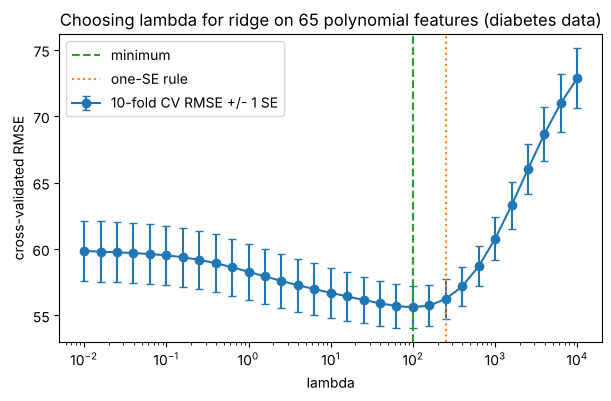

In [11]:
from sklearn.preprocessing import PolynomialFeatures

P = PolynomialFeatures(degree=2, include_bias=False).fit_transform(Xd)
P = (P - P.mean(axis=0)) / P.std(axis=0)
n_d = len(yd)
print("design matrix with degree-2 features:", P.shape)

def kfold_indices(n, k, g):
    return np.array_split(g.permutation(n), k)

def ridge_with_intercept(Xtr, ytr, lam):
    mu, ym = Xtr.mean(axis=0), ytr.mean()
    b = np.linalg.solve((Xtr - mu).T @ (Xtr - mu) + lam * np.eye(Xtr.shape[1]), (Xtr - mu).T @ (ytr - ym))
    return b, mu, ym

def cv_ridge(X, y, lam, folds):
    fold_mse = []
    for f in range(len(folds)):
        test = folds[f]
        train = np.concatenate([folds[g] for g in range(len(folds)) if g != f])
        b, mu, ym = ridge_with_intercept(X[train], y[train], lam)   # centring learned on the training fold only
        pred = (X[test] - mu) @ b + ym
        fold_mse.append(np.mean((y[test] - pred) ** 2))
    return np.array(fold_mse)

folds = kfold_indices(n_d, 10, np.random.default_rng(0))
lams = np.logspace(-2, 4, 31)
cv = np.array([cv_ridge(P, yd, lam, folds) for lam in lams])          # shape (31, 10)
cv_mean, cv_se = cv.mean(axis=1), cv.std(axis=1, ddof=1) / np.sqrt(10)
i_best = int(np.argmin(cv_mean))
i_1se = int(np.max(np.where(cv_mean <= cv_mean[i_best] + cv_se[i_best])[0]))
print(f"lambda minimising CV error: {lams[i_best]:.1f}  (CV RMSE {np.sqrt(cv_mean[i_best]):.2f})")
print(f"one-standard-error rule:    {lams[i_1se]:.1f}  (CV RMSE {np.sqrt(cv_mean[i_1se]):.2f})")
print(f"for comparison, OLS on the 65 features (lambda -> 0): CV RMSE {np.sqrt(cv_mean[0]):.2f}")

plt.errorbar(lams, np.sqrt(cv_mean), yerr=cv_se / (2 * np.sqrt(cv_mean)), fmt="o-", capsize=3, label="10-fold CV RMSE +/- 1 SE")
plt.axvline(lams[i_best], color="tab:green", ls="--", label="minimum")
plt.axvline(lams[i_1se], color="tab:orange", ls=":", label="one-SE rule")
plt.xscale("log"); plt.title("Choosing lambda for ridge on 65 polynomial features (diabetes data)")
plt.xlabel("lambda"); plt.ylabel("cross-validated RMSE"); plt.legend(); plt.show()

The curve is the U of Section 8 seen through cross-validation: too little penalty and the 65
features overfit; too much and the model is pulled towards the mean. The minimum sits around
$\lambda \approx 100$, and the one-standard-error rule picks a larger, simpler model that is
statistically indistinguishable from it.

### The leave-one-out shortcut

For any linear smoother $\hat y = Hy$ the leave-one-out error needs no refitting:
$\operatorname{CV}_{\text{LOO}} = \frac1n\sum_i\big(\frac{y_i - \hat y_i}{1 - h_{ii}}\big)^2$.
We verify it against brute force (442 refits) for ridge; `RidgeCV` uses the same identity.

In [12]:
import time
from sklearn.linear_model import RidgeCV

def loo_ridge_shortcut(X, y, lam):
    Xc, yc = X - X.mean(axis=0), y - y.mean()
    H = Xc @ np.linalg.solve(Xc.T @ Xc + lam * np.eye(X.shape[1]), Xc.T)
    h = np.diag(H) + 1.0 / len(y)                    # + 1/n: the intercept's share of the leverage
    e = yc - H @ yc
    return np.mean((e / (1 - h)) ** 2)

def loo_ridge_brute(X, y, lam):
    errs = []
    for i in range(len(y)):
        m = np.ones(len(y), bool); m[i] = False
        b, mu, ym = ridge_with_intercept(X[m], y[m], lam)
        errs.append((y[i] - ((X[i] - mu) @ b + ym)) ** 2)
    return np.mean(errs)

lam = 100.0
t0 = time.time(); loo_fast = loo_ridge_shortcut(P, yd, lam); t_fast = time.time() - t0
t0 = time.time(); loo_slow = loo_ridge_brute(P, yd, lam); t_slow = time.time() - t0
print(f"LOO MSE at lambda = {lam:g}: shortcut {loo_fast:.6f} ({t_fast*1e3:.1f} ms)   brute force {loo_slow:.6f} ({t_slow*1e3:.0f} ms)")
loo_curve = np.array([loo_ridge_shortcut(P, yd, l) for l in lams])
rcv = RidgeCV(alphas=lams).fit(P, yd)                # efficient LOO internally
print(f"LOO-optimal lambda: ours {lams[np.argmin(loo_curve)]:.1f}   sklearn RidgeCV {rcv.alpha_:.1f}")

LOO MSE at lambda = 100: shortcut 3082.559939 (2.3 ms)   brute force 3082.559939 (168 ms)
LOO-optimal lambda: ours 100.0   sklearn RidgeCV 100.0


The shortcut agrees with 442 explicit refits to every printed digit and runs hundreds of times
faster. (The extra $1/n$ in the leverage is the intercept's contribution: the fitted value
$\bar y + \hat\beta^\top(x_i - \bar x)$ is a linear smoother whose hat matrix is
$\frac1n\mathbf{1}\mathbf{1}^\top + H_c$.)

### Learning curves

Finally, plot training and validation error against the training-set size $n$ for an
underfitting, a reasonable and an overfitting model.

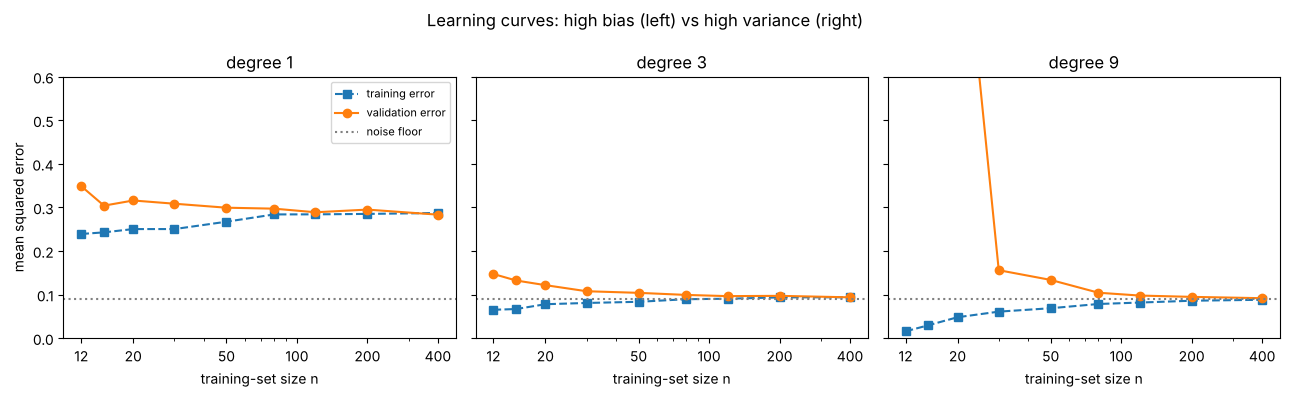

In [13]:
def learning_curve(degree, sizes, n_rep=40, sigma=0.3, seed=1):
    g = np.random.default_rng(seed)
    tr, va = [], []
    for n in sizes:
        tr_n, va_n = [], []
        for _ in range(n_rep):
            x = g.uniform(0, 1, n); y = f_true(x) + sigma * g.normal(size=n)
            coef = np.polyfit(x, y, degree)
            tr_n.append(np.mean((np.polyval(coef, x) - y) ** 2))
            xv = g.uniform(0, 1, 500); yv = f_true(xv) + sigma * g.normal(size=500)
            va_n.append(np.mean((np.polyval(coef, xv) - yv) ** 2))
        tr.append(np.mean(tr_n)); va.append(np.median(va_n))     # median: degree 9 at n = 12 has wild outliers
    return np.array(tr), np.array(va)

sizes = np.array([12, 15, 20, 30, 50, 80, 120, 200, 400])
fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
for ax, d in zip(axes, [1, 3, 9]):
    tr, va = learning_curve(d, sizes)
    ax.semilogx(sizes, tr, "s--", label="training error")
    ax.semilogx(sizes, va, "o-", label="validation error")
    ax.axhline(sigma ** 2, color="gray", ls=":", label="noise floor")
    ax.set_ylim(0, 0.6); ax.set_title(f"degree {d}"); ax.set_xlabel("training-set size n")
    ax.set_xticks([12, 20, 50, 100, 200, 400]); ax.set_xticklabels(["12", "20", "50", "100", "200", "400"])
    ax.xaxis.set_minor_formatter(plt.NullFormatter())
axes[0].set_ylabel("mean squared error"); axes[0].legend(fontsize=8)
fig.suptitle("Learning curves: high bias (left) vs high variance (right)")
plt.tight_layout(); plt.show()

Degree 1: the two curves meet almost immediately at a high plateau — more data cannot help a
model that cannot represent the truth. Degree 9: a large gap at small $n$ that closes slowly as
$n$ grows — the signature of variance, and the case where more data *does* help. Degree 3
converges quickly to the noise floor. When a model disappoints, this plot tells you whether to
collect data or to change the model.

**Try it yourself:** the CV curve above used a single random fold assignment. Re-run the
CV cell with `np.random.default_rng(1)` for the folds. How much does the chosen $\lambda$
move? That variability is why nested CV is needed before you *report* the score of the
winner.

## 10. Diagnostics: residuals, leverage and multicollinearity

Three quick checks after any fit: residuals against fitted values (should be a structureless
band), leverage (points far out in feature space, $h_{ii} > 2p/n$), and variance inflation
factors $\operatorname{VIF}_j = 1/(1 - R_j^2)$ for correlated features.

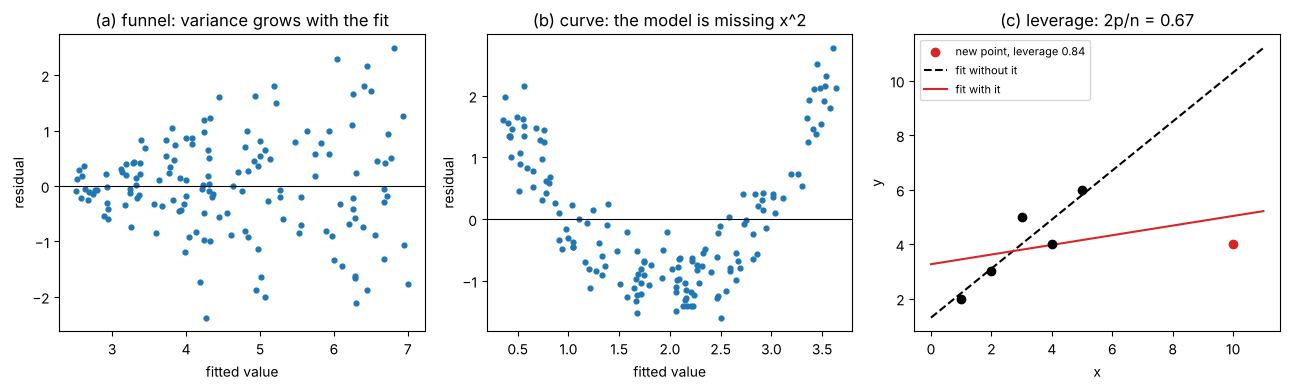

leverages with the extra point: [0.3639 0.259  0.1934 0.1672 0.1803 0.8361]

feature   VIF     OLS coefficient (standardised)
age        1.22      -0.48
sex        1.28     -11.41
bmi        1.51      24.73
bp         1.46      15.43
s1        59.20     -37.68   <- strongly collinear
s2        39.19      22.68   <- strongly collinear
s3        15.40       4.81   <- strongly collinear
s4         8.89       8.42
s5        10.08      35.73   <- strongly collinear
s6         1.48       3.22
correlation(s1, s2) = 0.897


In [14]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))

# (a) heteroscedastic noise: the funnel
xa = rng.uniform(1, 10, 150)
ya = 2 + 0.5 * xa + 0.15 * xa * rng.normal(size=150)      # noise grows with x
Xa = np.column_stack([np.ones(150), xa]); ba = np.linalg.lstsq(Xa, ya, rcond=None)[0]
axes[0].scatter(Xa @ ba, ya - Xa @ ba, s=12); axes[0].axhline(0, color="k", lw=0.8)
axes[0].set_title("(a) funnel: variance grows with the fit"); axes[0].set_xlabel("fitted value"); axes[0].set_ylabel("residual")

# (b) a missing non-linearity: the curve
xb_ = rng.uniform(-2, 2, 150)
yb_ = 1 + xb_ + 0.8 * xb_ ** 2 + 0.4 * rng.normal(size=150)
Xb_ = np.column_stack([np.ones(150), xb_]); bb = np.linalg.lstsq(Xb_, yb_, rcond=None)[0]
axes[1].scatter(Xb_ @ bb, yb_ - Xb_ @ bb, s=12); axes[1].axhline(0, color="k", lw=0.8)
axes[1].set_title("(b) curve: the model is missing x^2"); axes[1].set_xlabel("fitted value"); axes[1].set_ylabel("residual")

# (c) one high-leverage point steers the whole line
x_lev = np.r_[x5, 10.0]; y_lev = np.r_[y5, 4.0]
X_lev = np.column_stack([np.ones(6), x_lev])
H_lev = X_lev @ np.linalg.solve(X_lev.T @ X_lev, X_lev.T)
b_with = np.linalg.lstsq(X_lev, y_lev, rcond=None)[0]
b_without = np.linalg.lstsq(X5, y5, rcond=None)[0]
xx = np.linspace(0, 11, 50)
axes[2].scatter(x5, y5, color="k", zorder=3); axes[2].scatter([10], [4], color="tab:red", zorder=3, label=f"new point, leverage {H_lev[-1, -1]:.2f}")
axes[2].plot(xx, b_without[0] + b_without[1] * xx, "k--", label="fit without it")
axes[2].plot(xx, b_with[0] + b_with[1] * xx, "tab:red", label="fit with it")
axes[2].set_title("(c) leverage: 2p/n = %.2f" % (2 * 2 / 6)); axes[2].set_xlabel("x"); axes[2].set_ylabel("y"); axes[2].legend(fontsize=8)
plt.tight_layout(); plt.show()
print("leverages with the extra point:", np.diag(H_lev))

# variance inflation factors on the diabetes features
def vif(X):
    out = []
    for j in range(X.shape[1]):
        others = np.column_stack([np.ones(len(X)), np.delete(X, j, axis=1)])
        bj = np.linalg.lstsq(others, X[:, j], rcond=None)[0]
        r2 = 1 - ((X[:, j] - others @ bj) ** 2).sum() / ((X[:, j] - X[:, j].mean()) ** 2).sum()
        out.append(1 / (1 - r2))
    return np.array(out)
v = vif(Xd_s)
b_ols_d = np.linalg.lstsq(np.column_stack([np.ones(n_d), Xd_s]), yd, rcond=None)[0][1:]
print("\nfeature   VIF     OLS coefficient (standardised)")
for name, vj, bj in zip(names, v, b_ols_d):
    print(f"{name:7s} {vj:7.2f}   {bj:8.2f}" + ("   <- strongly collinear" if vj > 10 else ""))
print("correlation(s1, s2) = %.3f" % np.corrcoef(Xd_s[:, 4], Xd_s[:, 5])[0, 1])

Panel (a) is heteroscedasticity: the OLS coefficients are still unbiased but the standard
errors and prediction intervals are wrong (too narrow where the noise is large). Panel (b)
says the model is missing a term — a quadratic fixes it. Panel (c) shows a single point with
leverage $0.84$ (the threshold $2p/n$ is $0.67$) rotating the fitted line; a point like this
deserves a check of the data before it is allowed to vote. The VIF table explains the diabetes
coefficients: `s1` and `s2` are correlated at $0.90$, inflate each other's variance by factors
of 59 and 39, and receive large OLS coefficients of opposite sign — the same symptom as
$x_0, x_1$ in Section 4, and the reason the lasso path in Section 5 kept only one of them.

## Summary

- Training error estimates the empirical risk and flatters flexible models; only fresh data
  (or cross-validation) estimates the true risk.
- OLS is one answer with three derivations — projection, zero gradient, Gaussian maximum
  likelihood; the hat matrix $H$ gives fitted values, leverages and the LOO shortcut.
- Basis expansion keeps the model linear in its coefficients while bending in $x$; standardise
  before adding powers or penalties.
- Ridge multiplies each singular-direction component by $d_j^2/(d_j^2 + \lambda)$: the directions
  the data barely constrain are shrunk first; $\operatorname{df}(\lambda)$ measures what is left.
- Lasso is soft-thresholding; coordinate descent solves it in a few lines and produces exact
  zeros; among correlated features the choice is arbitrary but the selection is not.
- Logistic and Poisson regression are GLMs: score $X^\top(y - \mu)$, Newton = IRLS; on
  separable data the unpenalised MLE does not exist.
- Expected squared error = noise + bias² + variance, measurable by simulation; complexity and
  regularisation move along the same trade-off.
- $k$-fold CV with error bars, the one-standard-error rule and learning curves tell you how
  much to regularise and whether more data would help; nested CV keeps the reported score honest.
- Residual plots, leverage and VIF catch heteroscedasticity, influential points and
  collinearity before they reach production.

## Next: open `exercises.ipynb`

Twelve exercises with instant self-checks, from the normal equations to an end-to-end
regularised regression with nested cross-validation and a bootstrap confidence interval.